1.Importing The Dependencies

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split,cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
import pickle


**2.Data Loading and Understanding**

In [5]:
# Load The Csv Data
# TELECOM CUSTOMER CHURN DATA

df = pd.read_csv("/content/WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [6]:
df.shape

(7043, 21)

In [7]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


NO NULL VALUES

In [9]:
# Dropping Customer ID column as this is not required for modelling
df = df.drop(columns='customerID')

In [10]:
df.head(2)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No


In [11]:
# Printing the unique values in all the columns
numerical_feature_list = ["tenure",'MonthlyCharges','TotalCharges']

for col in df.columns:
  if col  not in numerical_feature_list:

    print(col,df[col].unique())
    print("-"*50)

gender ['Female' 'Male']
--------------------------------------------------
SeniorCitizen [0 1]
--------------------------------------------------
Partner ['Yes' 'No']
--------------------------------------------------
Dependents ['No' 'Yes']
--------------------------------------------------
PhoneService ['No' 'Yes']
--------------------------------------------------
MultipleLines ['No phone service' 'No' 'Yes']
--------------------------------------------------
InternetService ['DSL' 'Fiber optic' 'No']
--------------------------------------------------
OnlineSecurity ['No' 'Yes' 'No internet service']
--------------------------------------------------
OnlineBackup ['Yes' 'No' 'No internet service']
--------------------------------------------------
DeviceProtection ['No' 'Yes' 'No internet service']
--------------------------------------------------
TechSupport ['No' 'Yes' 'No internet service']
--------------------------------------------------
StreamingTV ['No' 'Yes' 'No internet 

In [12]:
df.isnull().sum()

,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0
OnlineBackup,0


In [14]:
# df["TotalCharges"] = df["TotalCharges"].astype(float)

ValueError: could not convert string to float: ' '

In [15]:
# empty spaces are filled with " " value not NAN

df[df['TotalCharges']==" "]

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [16]:
len(df[df['TotalCharges']==" "])

11

In [19]:
df['TotalCharges']= df['TotalCharges'].replace((" ","0.0"))

/tmp/ipykernel_5830/850266332.py:1: FutureWarning: Series.replace without 'value' and with non-dict-like 'to_replace' is deprecated and will raise in a future version. Explicitly specify the new values instead.
  df['TotalCharges']= df['TotalCharges'].replace((" ","0.0"))


In [20]:
df["TotalCharges"] = df["TotalCharges"].astype(float)

In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


In [23]:
# Checkiing the distrubution of target column

print(df['Churn'].value_counts())

Churn
No     5174
Yes    1869
Name: count, dtype: int64


**INSIGHTS**

1.CustomerId removed as it is not required for the model creation

2.no missing vakues in the dataset

3.Missing values in the Totalcharges column are replaced with 0.

4.No class imbalance indentified in the target

**EDA**

In [24]:
df.head(2)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No


In [25]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2285.169963
std,0.368612,24.559481,30.090047,2267.544511
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,401.675000
50%,0.000000,29.000000,70.350000,1398.250000
75%,0.000000,55.000000,89.850000,3803.050000
max,1.000000,72.000000,118.750000,8684.800000


NUMERICAL FEATURE ANALYSIS

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_histogram(df, column_name):
    plt.figure(figsize=(5, 3))

    sns.histplot(df[column_name], kde=True)

    plt.title(f"Distribution of {column_name}")
    plt.xlabel(column_name)
    plt.ylabel("Frequency")

    # Calculate mean and median
    mean_value = df[column_name].mean()
    median_value = df[column_name].median()

    # Add vertical lines for mean and median
    plt.axvline(
        mean_value,
        color='red',
        linestyle='dashed',
        linewidth=1,
        label=f'Mean: {mean_value:.2f}'
    )

    plt.axvline(
        median_value,
        color='green',
        linestyle='dashed',
        linewidth=1,
        label=f'Median: {median_value:.2f}'
    )

    plt.legend()
    plt.show()

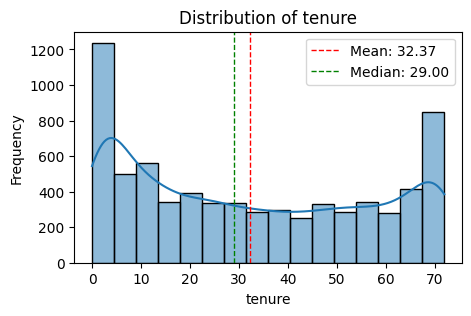

In [37]:
plot_histogram(df,'tenure')

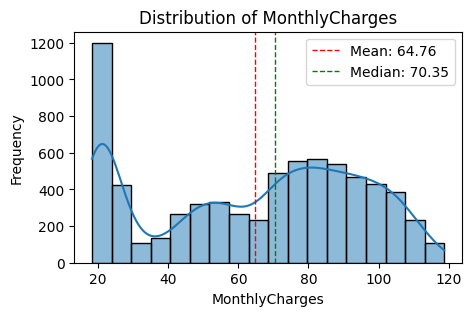

In [38]:
plot_histogram(df,'MonthlyCharges')

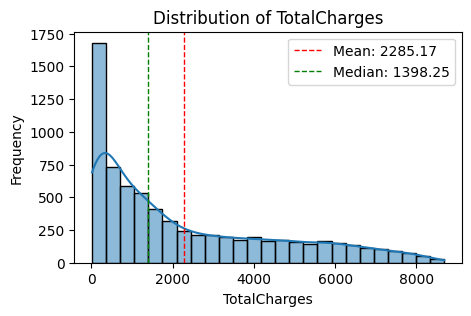

In [39]:
plot_histogram(df,'TotalCharges')

**BOX PLOT FOR NUMERICAL**

In [40]:
def plot_boxplot(df, column_name):
    plt.figure(figsize=(5, 3))
    sns.boxplot(x=df[column_name])
    plt.title(f"Boxplot of {column_name}")
    plt.ylabel(column_name)
    plt.show()



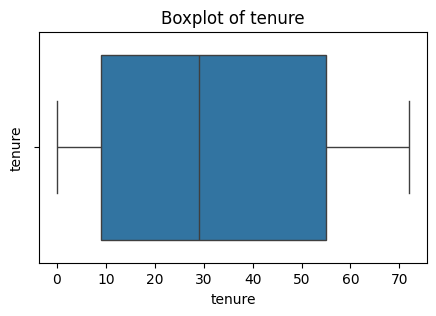

In [43]:
plot_boxplot(df,'tenure')

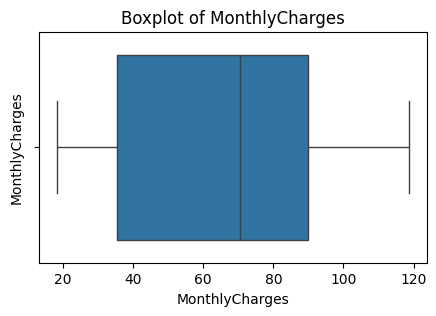

In [44]:
plot_boxplot(df,'MonthlyCharges')

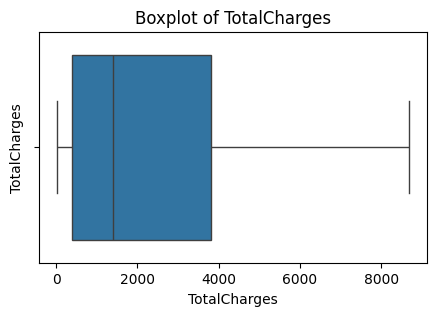

In [45]:
plot_boxplot(df,'TotalCharges')

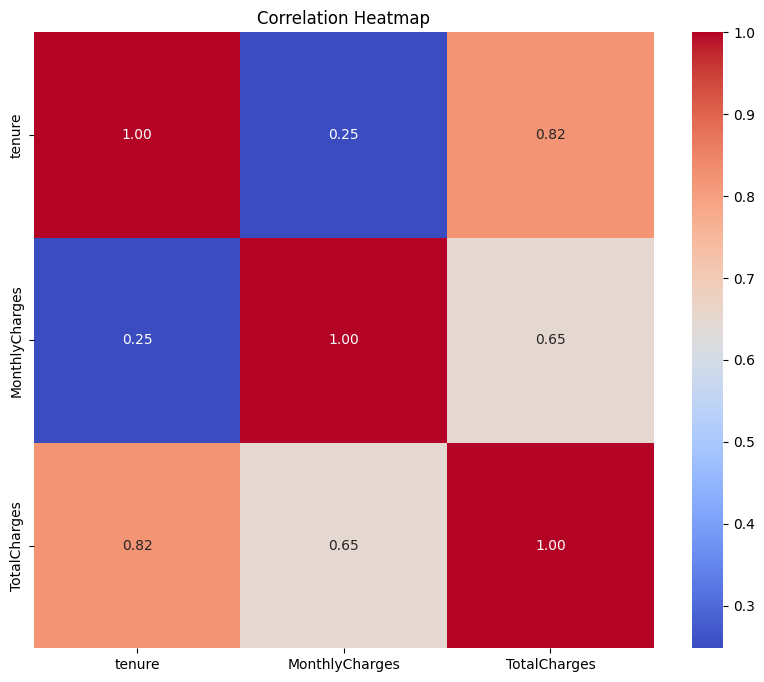

In [48]:
# Correlation matrix -- Heatmap

plt.figure(figsize=(10, 8))

sns.heatmap(
    df[['tenure', 'MonthlyCharges', 'TotalCharges']].corr(),
    annot=True,
    cmap='coolwarm',
    fmt = '.2f'
)

plt.title("Correlation Heatmap")
plt.show()

**Categorical Features- ANALYSIS**

In [49]:
df.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [50]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


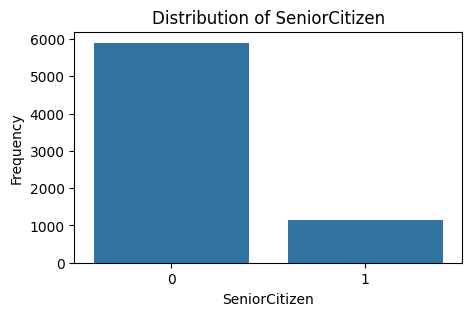

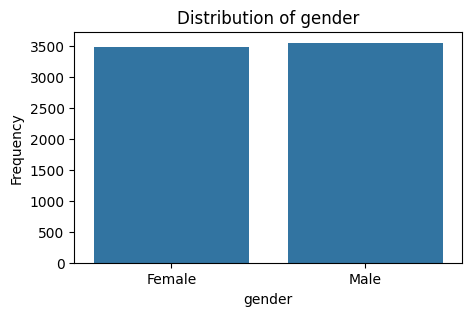

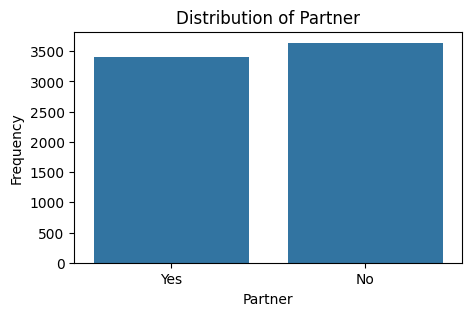

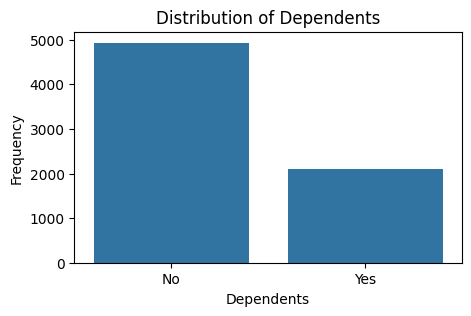

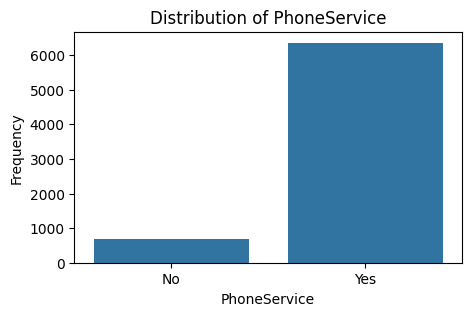

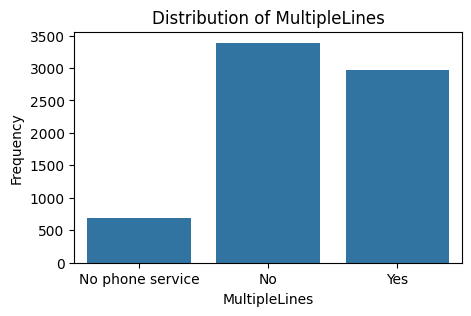

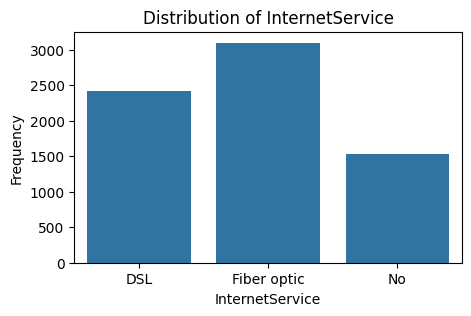

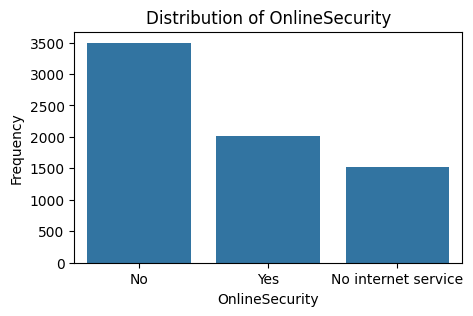

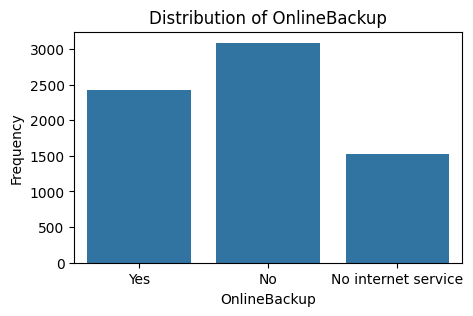

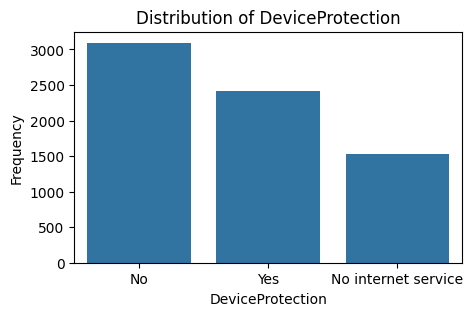

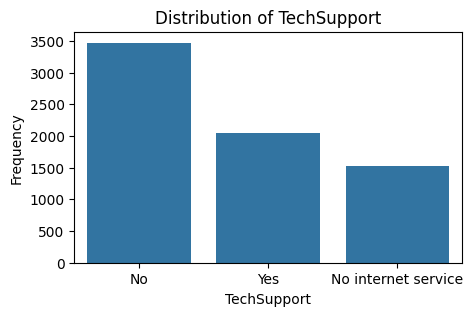

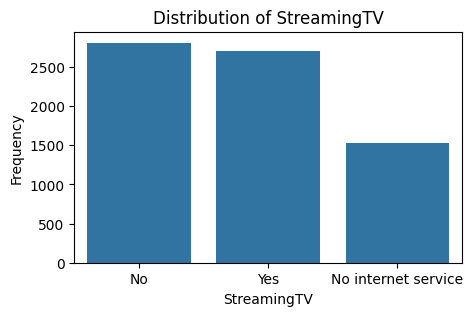

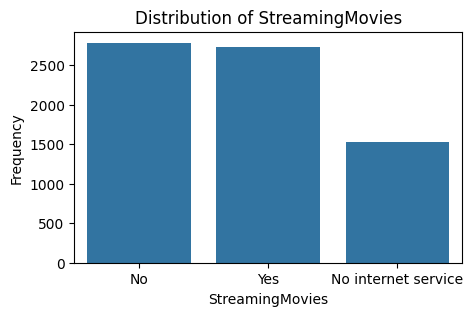

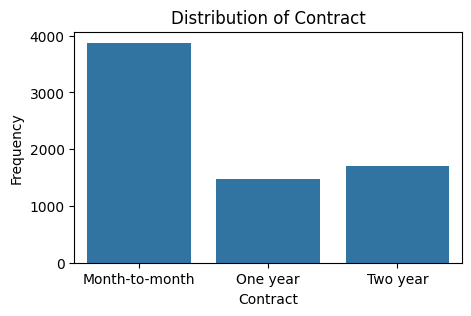

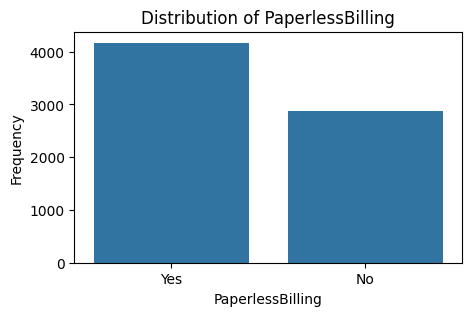

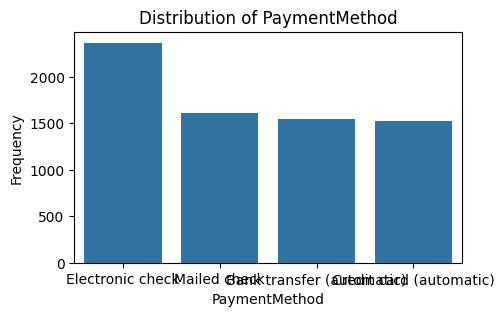

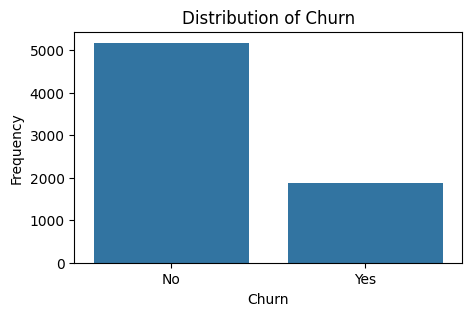

In [56]:
object_cols = df.select_dtypes(include='object').columns.tolist()
object_cols = ["SeniorCitizen"]+ object_cols

for col in object_cols:
  plt.figure(figsize=(5, 3))
  sns.countplot(x=df[col])
  plt.title(f"Distribution of {col}")
  plt.xlabel(col)
  plt.ylabel("Frequency")
  plt.show()

In [57]:
object_cols

['SeniorCitizen',
 'gender',
 'Partner',
 'Dependents',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'Churn']

**DATA PREPROCESSiNG**

In [58]:
df.head(2)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No


**LABEL ENCODING WITH TARGET COLUMN**

In [61]:
df['Churn']= df["Churn"].replace({"Yes":1,"No":0})

/tmp/ipykernel_5830/273305987.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['Churn']= df["Churn"].replace({"Yes":1,"No":0})


In [62]:
df.head(3)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1


In [63]:
df["Churn"].value_counts()

,count
Churn,
0,5174
1,1869


**LABEL ENCODING FOR cATEGORICAL COLUMN**

In [64]:
# Identifying columns with obeject data types

object_columns = df.select_dtypes(include = 'object').columns

In [65]:
print(object_columns)

Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='object')


In [66]:
# initialize a dict to save the encoders
encoders = {}

# apply the encoding and store the encoders
for column in object_columns:
  label_encoder = LabelEncoder()
  df[column] = label_encoder.fit_transform(df[column])
  encoders[column] = label_encoder

#save the encoders to a pickle files
with open("encoder.pkl","wb") as f:
  pickle.dump(encoders,f)

In [67]:
encoders

{'gender': LabelEncoder(),
 'Partner': LabelEncoder(),
 'Dependents': LabelEncoder(),
 'PhoneService': LabelEncoder(),
 'MultipleLines': LabelEncoder(),
 'InternetService': LabelEncoder(),
 'OnlineSecurity': LabelEncoder(),
 'OnlineBackup': LabelEncoder(),
 'DeviceProtection': LabelEncoder(),
 'TechSupport': LabelEncoder(),
 'StreamingTV': LabelEncoder(),
 'StreamingMovies': LabelEncoder(),
 'Contract': LabelEncoder(),
 'PaperlessBilling': LabelEncoder(),
 'PaymentMethod': LabelEncoder()}

In [68]:
df.head(5)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,1,0,1,0,0,2,0,0,0,0,0,1,2,29.85,29.85,0
1,1,0,0,0,34,1,0,0,2,0,2,0,0,0,1,0,3,56.95,1889.50,0
2,1,0,0,0,2,1,0,0,2,2,0,0,0,0,0,1,3,53.85,108.15,1
3,1,0,0,0,45,0,1,0,2,0,2,2,0,0,1,0,0,42.30,1840.75,0
4,0,0,0,0,2,1,0,1,0,0,0,0,0,0,0,1,2,70.70,151.65,1


In [69]:
# Separate features and target

X = df.drop('Churn', axis=1)
y = df['Churn']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (7043, 19)
y shape: (7043,)


In [70]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (5634, 19)
X_test : (1409, 19)
y_train: (5634,)
y_test : (1409,)


In [71]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape :", X_test_scaled.shape)

Training data shape: (5634, 19)
Testing data shape : (1409, 19)


In [72]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_scaled,
    y_train
)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

Before SMOTE:
Churn
0    4139
1    1495
Name: count, dtype: int64

After SMOTE:
Churn
0    4139
1    4139
Name: count, dtype: int64


In [73]:
# MLP using NUMPY

def sigmoid(x):
    return 1 / (1 + np.exp(-np.clip(x, -500, 500)))


def sigmoid_derivative(x):
    s = sigmoid(x)
    return s * (1 - s)


def tanh(x):
    return np.tanh(x)


def tanh_derivative(x):
    return 1 - np.tanh(x) ** 2


def relu(x):
    return np.maximum(0, x)


def relu_derivative(x):
    return (x > 0).astype(float)

In [74]:
class MLP:

    def __init__(self, input_size, hidden_size=16, learning_rate=0.01):

        self.learning_rate = learning_rate

        # Initialize weights
        self.W1 = np.random.randn(input_size, hidden_size) * 0.01
        self.b1 = np.zeros((1, hidden_size))

        self.W2 = np.random.randn(hidden_size, 1) * 0.01
        self.b2 = np.zeros((1, 1))


    def forward(self, X):

        # Hidden layer
        self.Z1 = np.dot(X, self.W1) + self.b1
        self.A1 = relu(self.Z1)

        # Output layer
        self.Z2 = np.dot(self.A1, self.W2) + self.b2
        self.A2 = sigmoid(self.Z2)

        return self.A2


    def compute_loss(self, y, y_pred):

        y = np.array(y).reshape(-1, 1)

        epsilon = 1e-8

        loss = -np.mean(
            y * np.log(y_pred + epsilon) +
            (1-y) * np.log(1-y_pred + epsilon)
        )

        return loss


    def backward(self, X, y, y_pred):

        y = np.array(y).reshape(-1, 1)

        m = X.shape[0]

        # Output layer gradients
        dZ2 = y_pred - y

        dW2 = np.dot(self.A1.T, dZ2) / m
        db2 = np.sum(dZ2, axis=0, keepdims=True) / m

        # Hidden layer gradients
        dA1 = np.dot(dZ2, self.W2.T)
        dZ1 = dA1 * relu_derivative(self.Z1)

        dW1 = np.dot(X.T, dZ1) / m
        db1 = np.sum(dZ1, axis=0, keepdims=True) / m

        # Update weights
        self.W2 -= self.learning_rate * dW2
        self.b2 -= self.learning_rate * db2

        self.W1 -= self.learning_rate * dW1
        self.b1 -= self.learning_rate * db1


    def fit(self, X, y, epochs=100):

        losses = []

        for epoch in range(epochs):

            # Forward propagation
            y_pred = self.forward(X)

            # Loss
            loss = self.compute_loss(y, y_pred)

            # Backpropagation
            self.backward(X, y, y_pred)

            losses.append(loss)

            if (epoch + 1) % 10 == 0:
                print(f"Epoch {epoch+1}/{epochs}, Loss: {loss:.4f}")

        return losses


    def predict_proba(self, X):
        return self.forward(X)


    def predict(self, X):

        probabilities = self.predict_proba(X)

        return (probabilities >= 0.5).astype(int)

In [75]:
np.random.seed(42)

mlp_numpy = MLP(
    input_size=X_train_smote.shape[1],
    hidden_size=16,
    learning_rate=0.01
)

losses = mlp_numpy.fit(
    X_train_smote,
    y_train_smote,
    epochs=100
)

Epoch 10/100, Loss: 0.6932
Epoch 20/100, Loss: 0.6932
Epoch 30/100, Loss: 0.6931
Epoch 40/100, Loss: 0.6931
Epoch 50/100, Loss: 0.6931
Epoch 60/100, Loss: 0.6931
Epoch 70/100, Loss: 0.6931
Epoch 80/100, Loss: 0.6931
Epoch 90/100, Loss: 0.6931
Epoch 100/100, Loss: 0.6930


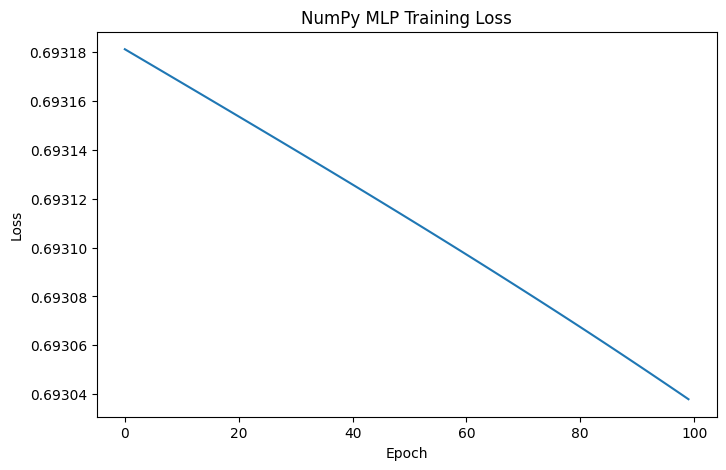

In [76]:
plt.figure(figsize=(8, 5))

plt.plot(losses)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("NumPy MLP Training Loss")

plt.show()

In [77]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [78]:
y_pred_numpy = mlp_numpy.predict(X_test_scaled).ravel()
y_prob_numpy = mlp_numpy.predict_proba(X_test_scaled).ravel()

print("NumPy MLP Results")
print("------------------")

print("Accuracy :", accuracy_score(y_test, y_pred_numpy))
print("Precision:", precision_score(y_test, y_pred_numpy))
print("Recall   :", recall_score(y_test, y_pred_numpy))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_numpy))

NumPy MLP Results
------------------
Accuracy : 0.39176721078779275
Precision: 0.29481733220050976
Recall   : 0.9278074866310161
ROC-AUC  : 0.6862641762897518


In [79]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

In [80]:
def create_model(activation='relu'):

    model = Sequential([

        Dense(
            32,
            activation=activation,
            input_shape=(X_train_smote.shape[1],)
        ),

        Dense(
            16,
            activation=activation
        ),

        Dense(
            1,
            activation='sigmoid'
        )
    ])

    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model

In [81]:
model_relu = create_model('relu')

history_relu = model_relu.fit(
    X_train_smote,
    y_train_smote,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    verbose=1
)

Epoch 1/50


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


207/207 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.7128 - loss: 0.5353 - val_accuracy: 0.6667 - val_loss: 0.6651
Epoch 2/50
207/207 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7679 - loss: 0.4665 - val_accuracy: 0.7258 - val_loss: 0.5939
Epoch 3/50
207/207 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7735 - loss: 0.4565 - val_accuracy: 0.7228 - val_loss: 0.6091
Epoch 4/50
207/207 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7792 - loss: 0.4503 - val_accuracy: 0.7132 - val_loss: 0.6089
Epoch 5/50
207/207 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7824 - loss: 0.4447 - val_accuracy: 0.7120 - val_loss: 0.6044
Epoch 6/50
207/207 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7847 - loss: 0.4418 - val_accuracy: 0.7560 - val_loss: 0.5376
Epoch 7/50
207/207 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7872 - loss: 0.4389 - val_accuracy: 0.7524 - val_loss: 0.5443
Epoch 8/50
207/207 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7918 - loss: 0.4360 - val_accuracy: 0.7397 - val_

In [82]:
y_prob_relu = model_relu.predict(X_test_scaled).ravel()

y_pred_relu = (y_prob_relu >= 0.5).astype(int)

print("ReLU Model")
print("----------")

print("Accuracy :", accuracy_score(y_test, y_pred_relu))
print("Precision:", precision_score(y_test, y_pred_relu))
print("Recall   :", recall_score(y_test, y_pred_relu))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_relu))

45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
ReLU Model
----------
Accuracy : 0.7579843860894251
Precision: 0.5413533834586466
Recall   : 0.5775401069518716
ROC-AUC  : 0.8134619855847477


In [83]:
model_tanh = create_model('tanh')

history_tanh = model_tanh.fit(
    X_train_smote,
    y_train_smote,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    verbose=1
)

Epoch 1/50


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


207/207 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.7229 - loss: 0.5345 - val_accuracy: 0.6830 - val_loss: 0.6390
Epoch 2/50
207/207 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7717 - loss: 0.4687 - val_accuracy: 0.7258 - val_loss: 0.5982
Epoch 3/50
207/207 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.7771 - loss: 0.4620 - val_accuracy: 0.6908 - val_loss: 0.6348
Epoch 4/50
207/207 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7744 - loss: 0.4585 - val_accuracy: 0.7186 - val_loss: 0.5950
Epoch 5/50
207/207 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7783 - loss: 0.4550 - val_accuracy: 0.7041 - val_loss: 0.6253
Epoch 6/50
207/207 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7768 - loss: 0.4523 - val_accuracy: 0.7283 - val_loss: 0.6072
Epoch 7/50
207/207 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7816 - loss: 0.4494 - val_accuracy: 0.7120 - val_loss: 0.6242
Epoch 8/50
207/207 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7824 - loss: 0.4472 - val_accuracy: 0.7228 - val_

In [84]:
y_prob_tanh = model_tanh.predict(X_test_scaled).ravel()

y_pred_tanh = (y_prob_tanh >= 0.5).astype(int)

print("Tanh Model")
print("----------")

print("Accuracy :", accuracy_score(y_test, y_pred_tanh))
print("Precision:", precision_score(y_test, y_pred_tanh))
print("Recall   :", recall_score(y_test, y_pred_tanh))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_tanh))

45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
Tanh Model
----------
Accuracy : 0.7615330021291696
Precision: 0.5467980295566502
Recall   : 0.5935828877005348
ROC-AUC  : 0.8064300291921775


In [85]:
model_sigmoid = create_model('sigmoid')

history_sigmoid = model_sigmoid.fit(
    X_train_smote,
    y_train_smote,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    verbose=1
)

Epoch 1/50


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


207/207 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.6700 - loss: 0.5982 - val_accuracy: 0.5604 - val_loss: 0.7840
Epoch 2/50
207/207 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.7661 - loss: 0.4957 - val_accuracy: 0.7077 - val_loss: 0.6957
Epoch 3/50
207/207 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7700 - loss: 0.4775 - val_accuracy: 0.7264 - val_loss: 0.6562
Epoch 4/50
207/207 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7703 - loss: 0.4720 - val_accuracy: 0.7246 - val_loss: 0.6507
Epoch 5/50
207/207 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7730 - loss: 0.4690 - val_accuracy: 0.7107 - val_loss: 0.6663
Epoch 6/50
207/207 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7745 - loss: 0.4671 - val_accuracy: 0.7452 - val_loss: 0.6179
Epoch 7/50
207/207 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7721 - loss: 0.4661 - val_accuracy: 0.7464 - val_loss: 0.6032
Epoch 8/50
207/207 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7718 - loss: 0.4647 - val_accuracy: 0.6957 - val_

In [86]:
y_prob_sigmoid = model_sigmoid.predict(X_test_scaled).ravel()

y_pred_sigmoid = (y_prob_sigmoid >= 0.5).astype(int)

print("Sigmoid Model")
print("-------------")

print("Accuracy :", accuracy_score(y_test, y_pred_sigmoid))
print("Precision:", precision_score(y_test, y_pred_sigmoid))
print("Recall   :", recall_score(y_test, y_pred_sigmoid))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_sigmoid))

45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Sigmoid Model
-------------
Accuracy : 0.7735982966643009
Precision: 0.5609756097560976
Recall   : 0.6764705882352942
ROC-AUC  : 0.8381771681004417


In [87]:
results = pd.DataFrame({
    'Model': [
        'Sigmoid',
        'Tanh',
        'ReLU'
    ],

    'Accuracy': [
        accuracy_score(y_test, y_pred_sigmoid),
        accuracy_score(y_test, y_pred_tanh),
        accuracy_score(y_test, y_pred_relu)
    ],

    'Precision': [
        precision_score(y_test, y_pred_sigmoid),
        precision_score(y_test, y_pred_tanh),
        precision_score(y_test, y_pred_relu)
    ],

    'Recall': [
        recall_score(y_test, y_pred_sigmoid),
        recall_score(y_test, y_pred_tanh),
        recall_score(y_test, y_pred_relu)
    ],

    'ROC-AUC': [
        roc_auc_score(y_test, y_prob_sigmoid),
        roc_auc_score(y_test, y_prob_tanh),
        roc_auc_score(y_test, y_prob_relu)
    ]
})

results

,Model,Accuracy,Precision,Recall,ROC-AUC
0,Sigmoid,0.773598,0.560976,0.676471,0.838177
1,Tanh,0.761533,0.546798,0.593583,0.806430
2,ReLU,0.757984,0.541353,0.577540,0.813462


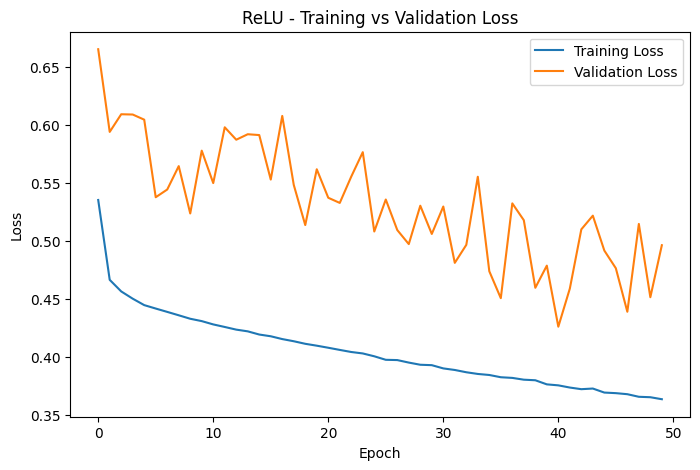

In [88]:
plt.figure(figsize=(8, 5))

plt.plot(history_relu.history['loss'], label='Training Loss')
plt.plot(history_relu.history['val_loss'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('ReLU - Training vs Validation Loss')
plt.legend()

plt.show()

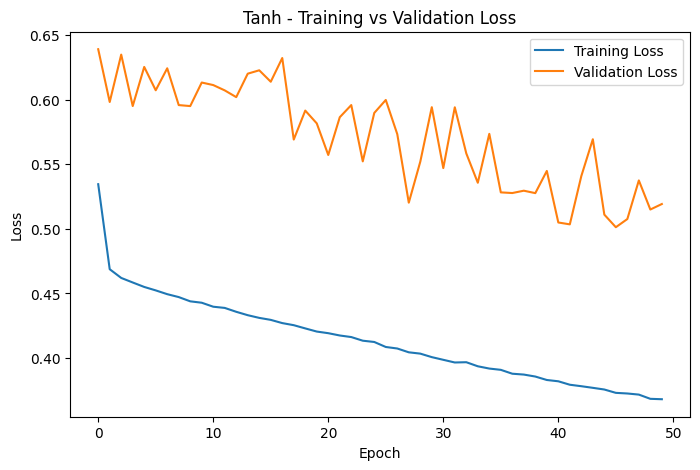

In [89]:
plt.figure(figsize=(8, 5))

plt.plot(history_tanh.history['loss'], label='Training Loss')
plt.plot(history_tanh.history['val_loss'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Tanh - Training vs Validation Loss')
plt.legend()

plt.show()

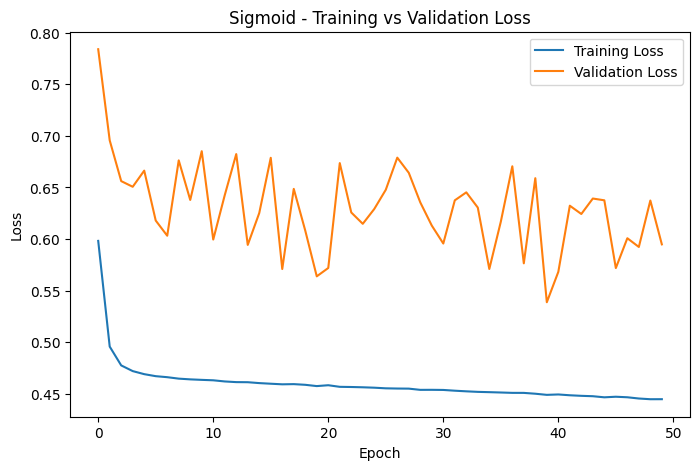

In [90]:
plt.figure(figsize=(8, 5))

plt.plot(history_sigmoid.history['loss'], label='Training Loss')
plt.plot(history_sigmoid.history['val_loss'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Sigmoid - Training vs Validation Loss')
plt.legend()

plt.show()

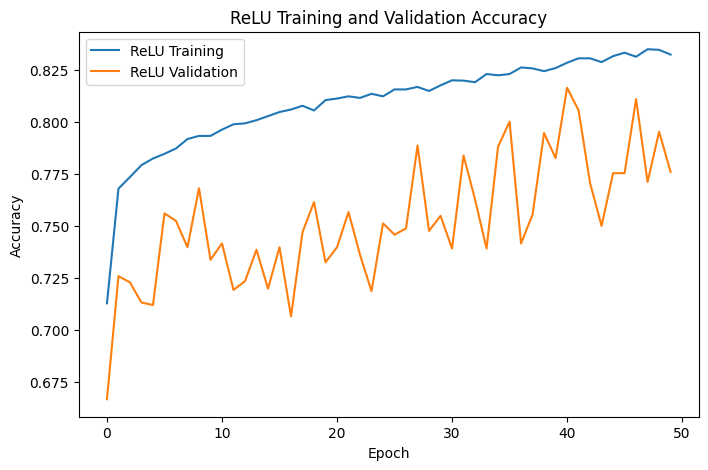

In [91]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_relu.history['accuracy'],
    label='ReLU Training'
)

plt.plot(
    history_relu.history['val_accuracy'],
    label='ReLU Validation'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('ReLU Training and Validation Accuracy')
plt.legend()

plt.show()

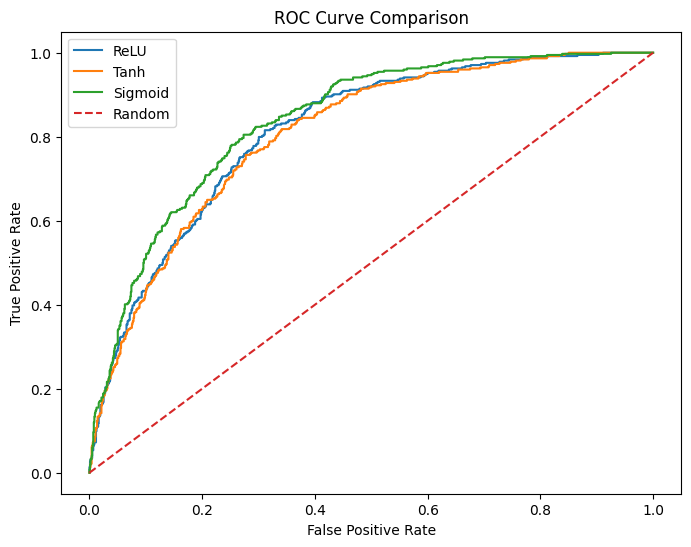

In [92]:
from sklearn.metrics import roc_curve

fpr_relu, tpr_relu, _ = roc_curve(y_test, y_prob_relu)
fpr_tanh, tpr_tanh, _ = roc_curve(y_test, y_prob_tanh)
fpr_sigmoid, tpr_sigmoid, _ = roc_curve(y_test, y_prob_sigmoid)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_relu,
    tpr_relu,
    label='ReLU'
)

plt.plot(
    fpr_tanh,
    tpr_tanh,
    label='Tanh'
)

plt.plot(
    fpr_sigmoid,
    tpr_sigmoid,
    label='Sigmoid'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')

plt.legend()
plt.show()